# Machine Learning Lab 8 

## Name : Nidhi Dharme 
## Class : A-A1-16

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.svm import SVC

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
df=pd.read_csv('ai4i2020.csv')

print("Dataset loaded successfully!")
print("Dataset Shape:",df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [6]:
print("Dataset Information")
print("-------------------")

print("\nNumber of Rows and Columns:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Dataset Information
-------------------

Number of Rows and Columns:
(10000, 14)

Column Names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Data Types:
UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------         

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000



Missing Values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Duplicate Records:
0


In [7]:
print("Machine Failure Distribution:")
print(df['Machine failure'].value_counts())

print("\nPercentage Distribution:")
print(df['Machine failure'].value_counts(normalize=True)*100)

Machine Failure Distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Percentage Distribution:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


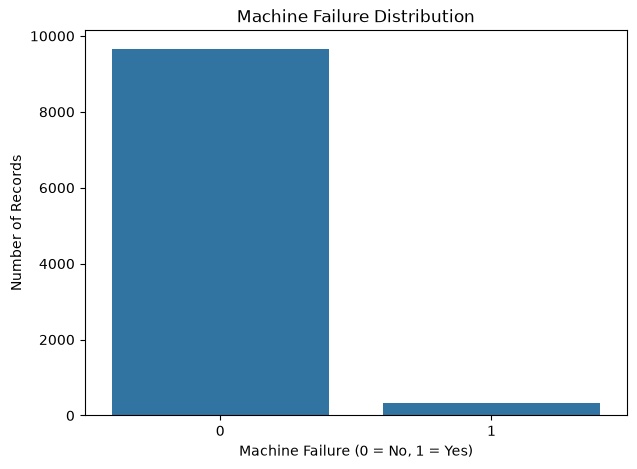

In [8]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x='Machine failure'
)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")

plt.show()

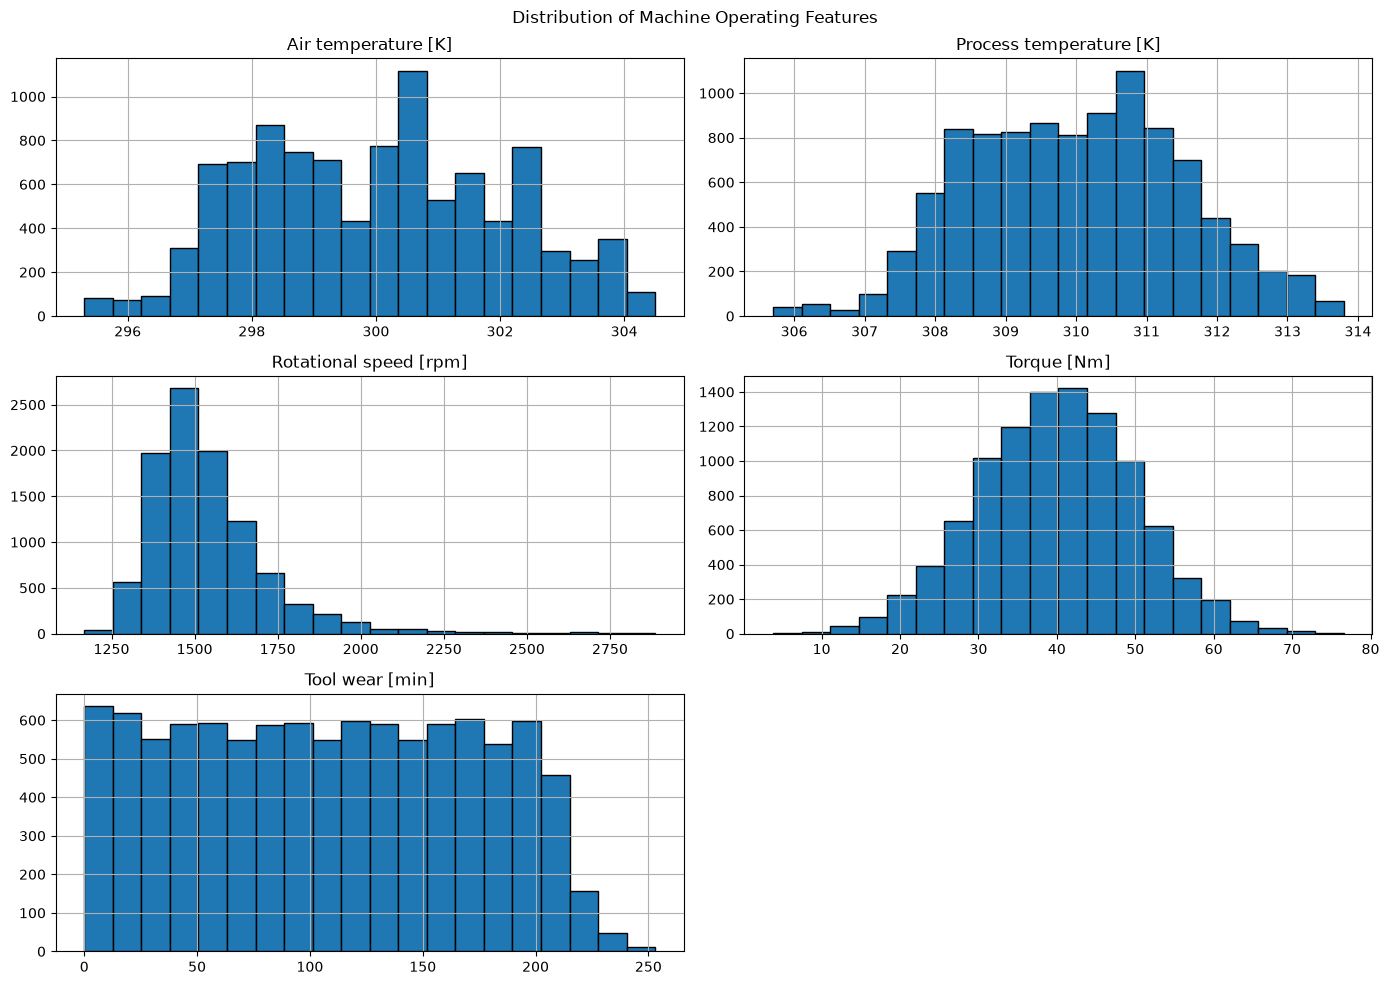

In [9]:
numerical_columns=[
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

df[numerical_columns].hist(
    figsize=(14,10),
    bins=20,
    edgecolor='black'
)

plt.suptitle("Distribution of Machine Operating Features")
plt.tight_layout()
plt.show()

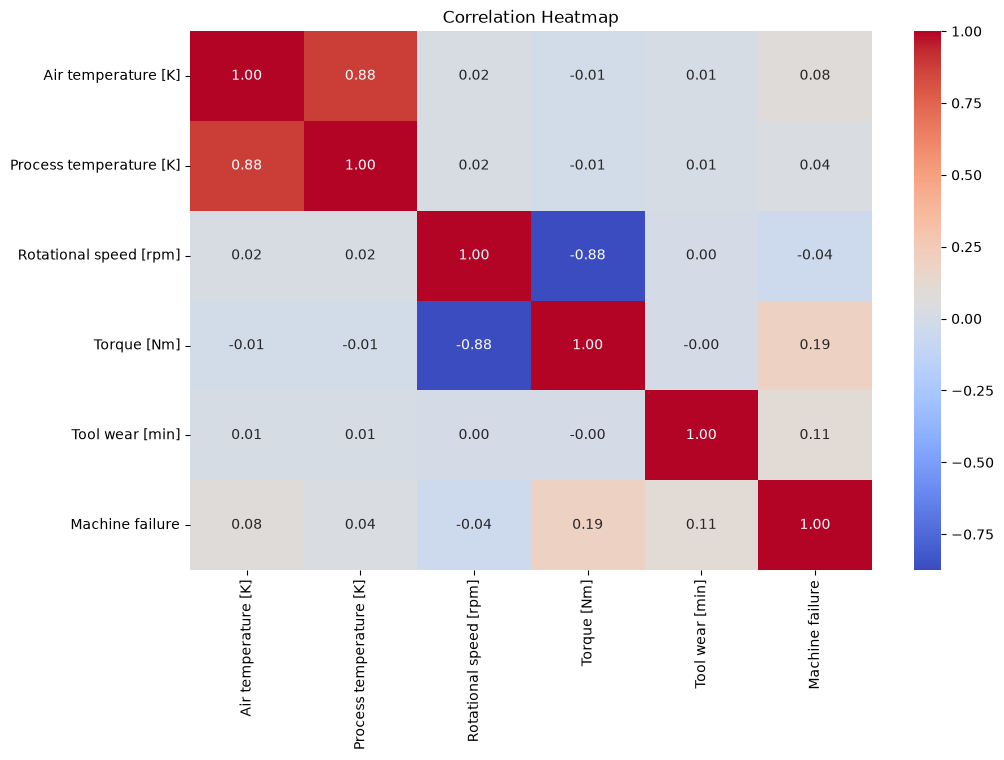

In [10]:
plt.figure(figsize=(11,7))

correlation=df[numerical_columns+['Machine failure']].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

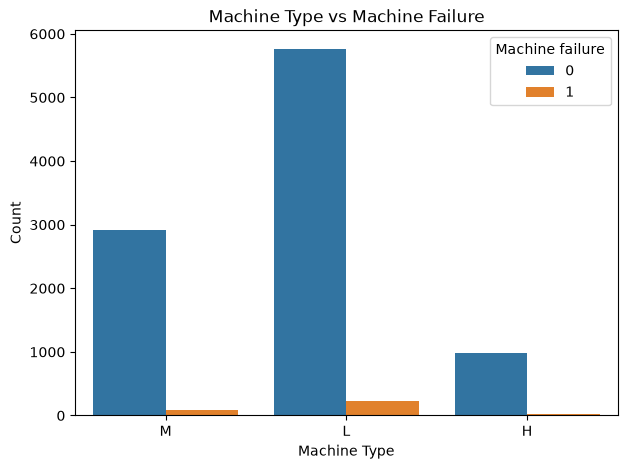

In [11]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x='Type',
    hue='Machine failure'
)

plt.title("Machine Type vs Machine Failure")
plt.xlabel("Machine Type")
plt.ylabel("Count")

plt.show()

In [12]:
X=df[
    [
        'Type',
        'Air temperature [K]',
        'Process temperature [K]',
        'Rotational speed [rpm]',
        'Torque [Nm]',
        'Tool wear [min]'
    ]
]

y=df['Machine failure']

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

print("\nNumber of Features:",X.shape[1])
print("Number of Target Classes:",y.nunique())

Input Features:
  Type  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
0    M                298.1                    308.6                    1551   
1    L                298.2                    308.7                    1408   
2    L                298.1                    308.5                    1498   
3    L                298.2                    308.6                    1433   
4    L                298.2                    308.7                    1408   

   Torque [Nm]  Tool wear [min]  
0         42.8                0  
1         46.3                3  
2         49.4                5  
3         39.5                7  
4         40.0                9  

Target Variable:
0    0
1    0
2    0
3    0
4    0
Name: Machine failure, dtype: int64

Number of Features: 6
Number of Target Classes: 2


In [13]:
numerical_features=X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features=X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

Categorical Features:
['Type']


In [14]:
numeric_transformer=Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='median')),
    ('scaler',StandardScaler())
])

categorical_transformer=Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('encoder',OneHotEncoder(handle_unknown='ignore'))
])

preprocessor=ColumnTransformer(
    transformers=[
        ('num',numeric_transformer,numerical_features),
        ('cat',categorical_transformer,categorical_features)
    ]
)

print("Data preprocessing completed successfully!")

Data preprocessing completed successfully!


In [15]:
X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:",X_train.shape)
print("Testing Data:",X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Data: (8000, 6)
Testing Data: (2000, 6)

Training Target Distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing Target Distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [16]:
linear_svm=Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('classifier',SVC(
        kernel='linear',
        C=1,
        class_weight='balanced'
    ))
])

linear_svm.fit(X_train,y_train)

print("Linear SVM model trained successfully!")

Linear SVM model trained successfully!


In [17]:
y_pred_linear=linear_svm.predict(X_test)

print("Linear SVM Predictions:")
print(y_pred_linear[:20])

print("\nActual Values:")
print(y_test.values[:20])

Linear SVM Predictions:
[1 1 1 0 1 1 1 0 0 0 0 0 0 0 0 1 0 1 0 0]

Actual Values:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0]


In [18]:
rbf_svm=Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('classifier',SVC(
        kernel='rbf',
        C=1,
        gamma='scale',
        class_weight='balanced'
    ))
])

rbf_svm.fit(X_train,y_train)

print("RBF SVM model trained successfully!")

RBF SVM model trained successfully!


In [19]:
y_pred_rbf=rbf_svm.predict(X_test)

print("RBF SVM Predictions:")
print(y_pred_rbf[:20])

print("\nActual Values:")
print(y_test.values[:20])

RBF SVM Predictions:
[1 0 1 0 0 1 1 0 0 0 0 0 0 0 1 0 0 1 0 0]

Actual Values:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0]


In [20]:
kernels=['linear','rbf','poly','sigmoid']

kernel_results=[]

for kernel in kernels:

    model=Pipeline(steps=[
        ('preprocessor',preprocessor),
        ('classifier',SVC(
            kernel=kernel,
            C=1,
            class_weight='balanced'
        ))
    ])

    model.fit(X_train,y_train)

    predictions=model.predict(X_test)

    kernel_results.append({
        'Kernel':kernel,
        'Accuracy':accuracy_score(y_test,predictions),
        'Precision':precision_score(y_test,predictions,zero_division=0),
        'Recall':recall_score(y_test,predictions,zero_division=0),
        'F1 Score':f1_score(y_test,predictions,zero_division=0)
    })

kernel_df=pd.DataFrame(kernel_results)

print("SVM Kernel Comparison:")
display(kernel_df.round(4))

SVM Kernel Comparison:


,Kernel,Accuracy,Precision,Recall,F1 Score
0,linear,0.8335,0.1504,0.8382,0.2550
1,rbf,0.9175,0.2785,0.8971,0.4251
2,poly,0.9130,0.2696,0.9118,0.4161
3,sigmoid,0.6090,0.0492,0.5735,0.0907


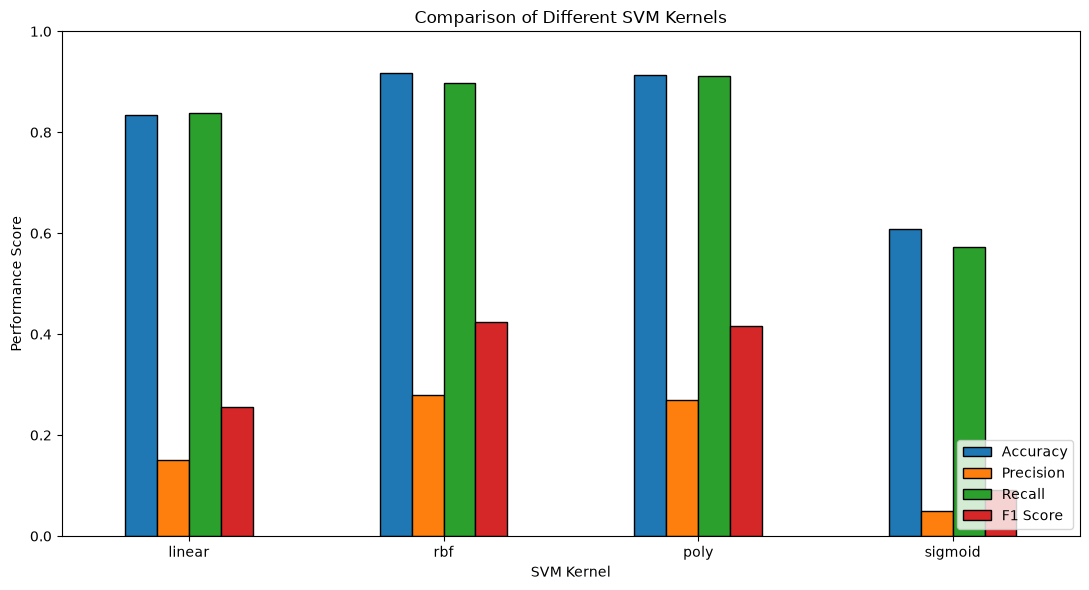

In [21]:
kernel_df.set_index('Kernel').plot(
    kind='bar',
    figsize=(11,6),
    ylim=(0,1),
    edgecolor='black'
)

plt.title("Comparison of Different SVM Kernels")
plt.xlabel("SVM Kernel")
plt.ylabel("Performance Score")
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [22]:
def evaluate_model(y_test,y_pred,model_name):

    print("\n",model_name)
    print("="*40)

    print("Accuracy:",accuracy_score(y_test,y_pred))

    print("Precision:",precision_score(
        y_test,y_pred,zero_division=0
    ))

    print("Recall:",recall_score(
        y_test,y_pred,zero_division=0
    ))

    print("F1 Score:",f1_score(
        y_test,y_pred,zero_division=0
    ))

evaluate_model(y_test,y_pred_linear,"Linear SVM")

evaluate_model(y_test,y_pred_rbf,"RBF SVM")


 Linear SVM
Accuracy: 0.8335
Precision: 0.1503957783641161
Recall: 0.8382352941176471
F1 Score: 0.2550335570469799

 RBF SVM
Accuracy: 0.9175
Precision: 0.2785388127853881
Recall: 0.8970588235294118
F1 Score: 0.4250871080139373


In [23]:
print("Linear SVM Classification Report:")
print(classification_report(
    y_test,
    y_pred_linear,
    target_names=['No Failure','Failure'],
    zero_division=0
))

print("\nRBF SVM Classification Report:")
print(classification_report(
    y_test,
    y_pred_rbf,
    target_names=['No Failure','Failure'],
    zero_division=0
))

Linear SVM Classification Report:
              precision    recall  f1-score   support

  No Failure       0.99      0.83      0.91      1932
     Failure       0.15      0.84      0.26        68

    accuracy                           0.83      2000
   macro avg       0.57      0.84      0.58      2000
weighted avg       0.96      0.83      0.88      2000


RBF SVM Classification Report:
              precision    recall  f1-score   support

  No Failure       1.00      0.92      0.96      1932
     Failure       0.28      0.90      0.43        68

    accuracy                           0.92      2000
   macro avg       0.64      0.91      0.69      2000
weighted avg       0.97      0.92      0.94      2000



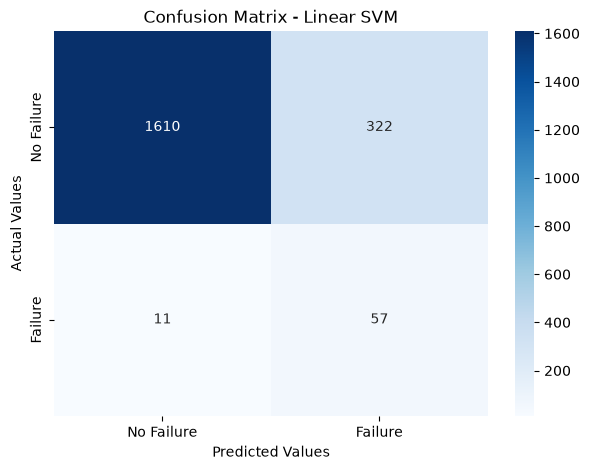

In [24]:
cm_linear=confusion_matrix(y_test,y_pred_linear)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm_linear,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Failure','Failure'],
    yticklabels=['No Failure','Failure']
)

plt.title("Confusion Matrix - Linear SVM")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

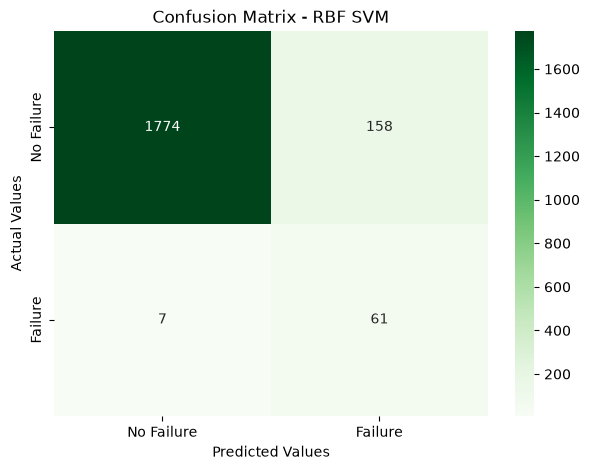

In [25]:
cm_rbf=confusion_matrix(y_test,y_pred_rbf)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm_rbf,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['No Failure','Failure'],
    yticklabels=['No Failure','Failure']
)

plt.title("Confusion Matrix - RBF SVM")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

In [26]:
param_grid={
    'classifier__C':[0.1,1,10,100],
    'classifier__gamma':['scale','auto',0.01,0.1,1],
    'classifier__kernel':['rbf']
}

print("Parameter Grid:")
print(param_grid)

Parameter Grid:
{'classifier__C': [0.1, 1, 10, 100], 'classifier__gamma': ['scale', 'auto', 0.01, 0.1, 1], 'classifier__kernel': ['rbf']}


In [27]:
grid_pipeline=Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('classifier',SVC(class_weight='balanced'))
])

grid_search=GridSearchCV(
    estimator=grid_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train,y_train)

print("\nGridSearchCV completed successfully!")

Fitting 5 folds for each of 20 candidates, totalling 100 fits

GridSearchCV completed successfully!


In [28]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross Validation F1 Score:")
print(grid_search.best_score_)

Best Parameters:
{'classifier__C': 100, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}

Best Cross Validation F1 Score:
0.5280108410352196


In [29]:
best_svm=grid_search.best_estimator_

y_pred_tuned=best_svm.predict(X_test)

print("Optimized SVM Predictions:")
print(y_pred_tuned[:20])

Optimized SVM Predictions:
[1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [30]:
evaluate_model(
    y_test,
    y_pred_tuned,
    "Optimized RBF SVM"
)


 Optimized RBF SVM
Accuracy: 0.9495
Precision: 0.37404580152671757
Recall: 0.7205882352941176
F1 Score: 0.49246231155778897


In [31]:
print("Optimized SVM Classification Report:")

print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=['No Failure','Failure'],
    zero_division=0
))

Optimized SVM Classification Report:
              precision    recall  f1-score   support

  No Failure       0.99      0.96      0.97      1932
     Failure       0.37      0.72      0.49        68

    accuracy                           0.95      2000
   macro avg       0.68      0.84      0.73      2000
weighted avg       0.97      0.95      0.96      2000



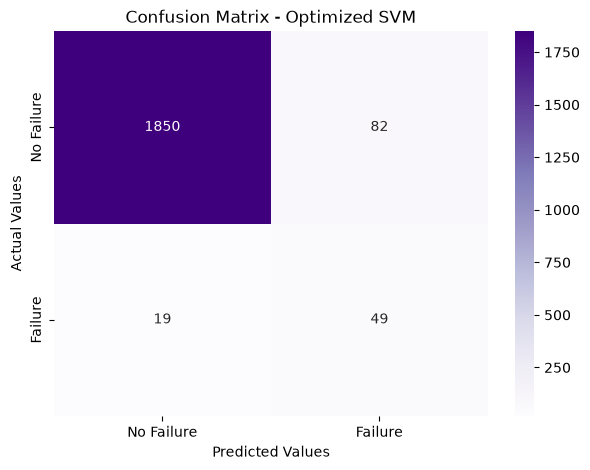

In [32]:
cm_tuned=confusion_matrix(y_test,y_pred_tuned)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm_tuned,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=['No Failure','Failure'],
    yticklabels=['No Failure','Failure']
)

plt.title("Confusion Matrix - Optimized SVM")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

In [33]:
models={
    'Linear SVM':y_pred_linear,
    'RBF SVM':y_pred_rbf,
    'Optimized RBF SVM':y_pred_tuned
}

final_results=[]

for name,predictions in models.items():

    final_results.append({
        'Model':name,
        'Accuracy':accuracy_score(y_test,predictions),
        'Precision':precision_score(y_test,predictions,zero_division=0),
        'Recall':recall_score(y_test,predictions,zero_division=0),
        'F1 Score':f1_score(y_test,predictions,zero_division=0)
    })

final_df=pd.DataFrame(final_results)

print("Final SVM Performance Comparison:")
display(final_df.round(4))

Final SVM Performance Comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,Linear SVM,0.8335,0.1504,0.8382,0.2550
1,RBF SVM,0.9175,0.2785,0.8971,0.4251
2,Optimized RBF SVM,0.9495,0.3740,0.7206,0.4925


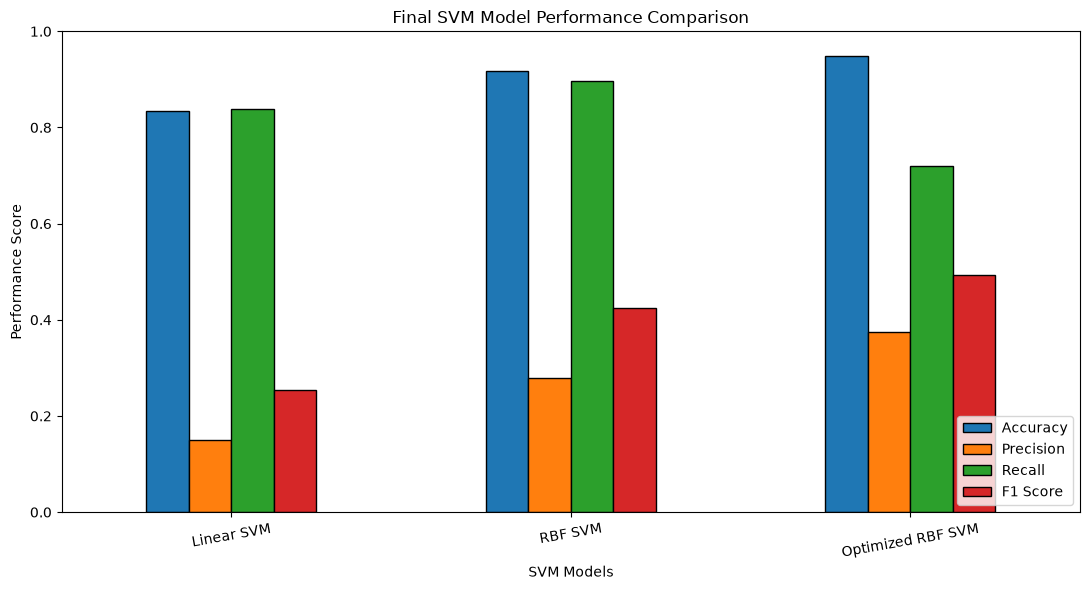

In [34]:
final_df.set_index('Model').plot(
    kind='bar',
    figsize=(11,6),
    ylim=(0,1),
    edgecolor='black'
)

plt.title("Final SVM Model Performance Comparison")
plt.xlabel("SVM Models")
plt.ylabel("Performance Score")
plt.xticks(rotation=10)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [35]:
kernel_df.to_csv('SVM_Kernel_Comparison.csv',index=False)

final_df.to_csv('SVM_Final_Results.csv',index=False)

print("All results saved successfully!")

All results saved successfully!
